# 01 — Dataset exploration

Load the data and display five random training images and five random test images.

In [4]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "scripts"))

from digit_dataset_config import PIXEL_COLUMNS
from digit_dataset_helpers import build_dataset_overview, load_datasets


In [5]:
datasets = load_datasets()
train = datasets["train"]
test = datasets["test"]


In [6]:
overview = build_dataset_overview(datasets)
print(f"train.csv shape: {overview['train']['shape']}")
print("Training label counts:")
for label, count in overview["train"]["label_counts"].items():
    print(f"  {label}: {count}")
print(f"\ntest.csv shape: {overview['test']['shape']}")


train.csv shape: (42000, 785)
Training label counts:
  0: 4132
  1: 4684
  2: 4177
  3: 4351
  4: 4072
  5: 3795
  6: 4137
  7: 4401
  8: 4063
  9: 4188

test.csv shape: (28000, 784)


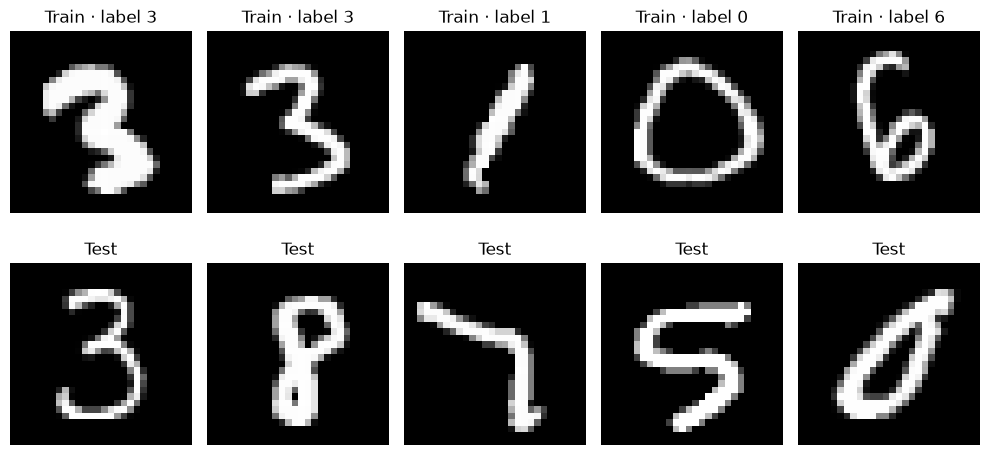

In [7]:
train_sample = train.sample(n=5)
test_sample = test.sample(n=5)

fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for column, (_, row) in enumerate(train_sample.iterrows()):
    image = row[PIXEL_COLUMNS].to_numpy().reshape(28, 28)
    axes[0, column].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[0, column].set_title(f"Train · label {int(row['label'])}")
    axes[0, column].axis("off")

for column, (_, row) in enumerate(test_sample.iterrows()):
    image = row[PIXEL_COLUMNS].to_numpy().reshape(28, 28)
    axes[1, column].imshow(image, cmap="gray", vmin=0, vmax=255)
    axes[1, column].set_title("Test")
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()
